In [1]:
import ROOT as rt
import os, sys
import json 
ERA = sys.argv[1]

# for dev
ERA = "combineall"

setting={}
with open('config/Settrain.json') as json_file:
    data = json.load(json_file)
    setting=data
SIGNAL_MASSES = setting["ALL_MASSES"]


def get_str_lumi_channel(era):
    if("mm" in era):
        str_channel="#mu#mu"          
    if("ee" in era):
        str_channel="ee"               
    if("em" in era):
        str_channel="e#mu"
    if("combine" in era):
        str_channel="combined"
    if "16pre" in era:
        str_lumi="19.52" 
    if "16post" in era:
        str_lumi="16.81"                 
    if "17" in era:
        str_lumi="41.48"
    if "18" in era:
        str_lumi="59.83"
    if "all" in era:
        str_lumi="137.2"
    return str_channel, str_lumi

str_channel, str_lumi = get_str_lumi_channel(ERA)
# channel="mm"
# # channel="combine"

# if channel=="mm":
#     str_channel="#mu#mu"
# #     limitz=11
# if channel=="ee":
#     str_channel="ee"
# #     limitz=12
# if channel=="em":
#     str_channel="e#mu"
# #     limitz=6.5
# if channel=="combine":
#     str_channel="combined"
str_lumi

Welcome to JupyROOT 6.26/08


'137.2'

In [2]:
import numpy as np
from scipy.interpolate import Rbf, interp1d
import itertools
#from GChiPairs import gchipairs
import operator
import subprocess
def set_palette(name="default", ncontours=255):
    # For the canvas:
    rt.gStyle.SetCanvasBorderMode(0)
    rt.gStyle.SetCanvasColor(rt.kWhite)
    rt.gStyle.SetCanvasDefH(400) #Height of canvas
    rt.gStyle.SetCanvasDefW(500) #Width of canvas
    rt.gStyle.SetCanvasDefX(0)   #POsition on screen
    rt.gStyle.SetCanvasDefY(0)
    
    # For the Pad:
    rt.gStyle.SetPadBorderMode(0)
    # rt.gStyle.SetPadBorderSize(Width_t size = 1)
    rt.gStyle.SetPadColor(rt.kWhite)
    rt.gStyle.SetPadGridX(False)
    rt.gStyle.SetPadGridY(False)
    rt.gStyle.SetGridColor(0)
    rt.gStyle.SetGridStyle(3)
    rt.gStyle.SetGridWidth(1)
    
    # For the frame:
    rt.gStyle.SetFrameBorderMode(0)
    rt.gStyle.SetFrameBorderSize(1)
    rt.gStyle.SetFrameFillColor(0)
    rt.gStyle.SetFrameFillStyle(0)
    rt.gStyle.SetFrameLineColor(1)
    rt.gStyle.SetFrameLineStyle(1)
    rt.gStyle.SetFrameLineWidth(1)
    
    # set the paper & margin sizes
    rt.gStyle.SetPaperSize(20,26)
    rt.gStyle.SetPadTopMargin(0.085)
    rt.gStyle.SetPadRightMargin(0.15)
    rt.gStyle.SetPadBottomMargin(0.15)
    rt.gStyle.SetPadLeftMargin(0.17)
    
    # use large Times-Roman fonts
    rt.gStyle.SetTitleFont(42,"xyz")  # set the all 3 axes title font
    rt.gStyle.SetTitleFont(42," ")    # set the pad title font
    rt.gStyle.SetTitleSize(0.06,"xyz") # set the 3 axes title size
    rt.gStyle.SetTitleSize(0.06," ")   # set the pad title size
    rt.gStyle.SetLabelFont(42,"xyz")
    rt.gStyle.SetLabelSize(0.05,"xyz")
    rt.gStyle.SetLabelColor(1,"xyz")
    rt.gStyle.SetTextFont(42)
    rt.gStyle.SetTextSize(0.08)
    rt.gStyle.SetStatFont(42)
    
    # use bold lines and markers
    rt.gStyle.SetMarkerStyle(8)
    #rt.gStyle.SetHistLineWidth(1.85)
    rt.gStyle.SetLineStyleString(2,"[12 12]") # postscript dashes
    
    #..Get rid of X error bars
    rt.gStyle.SetErrorX(0.001)
    
    # do not display any of the standard histogram decorations
    rt.gStyle.SetOptTitle(1)
    rt.gStyle.SetOptStat(0)
    #rt.gStyle.SetOptFit(11111111)
    rt.gStyle.SetOptFit(0)
    
    # put tick marks on top and RHS of plots
    rt.gStyle.SetPadTickX(1)
    rt.gStyle.SetPadTickY(1)
    # default palette, looks cool
    stops = [0.00, 0.34, 0.61, 0.84, 1.00]
    red   = [0.00, 0.00, 0.87, 1.00, 0.51]
    green = [0.00, 0.81, 1.00, 0.20, 0.00]
    blue  = [0.51, 1.00, 0.12, 0.00, 0.00]
    #from PlotsSMS/python/smsPlotXSEC.py
    stops = [0.00, 0.20, 0.70, 0.90, 1.00]
    red   = [0.00, 0.00, 1.00, 1.00, 1.00]
    green = [0.00, 1.00, 1.00, 0.30, 0.00]
    blue  = [1.00, 1.00, 0.00, 0.20, 0.00]

    s = array('d', stops)
    r = array('d', red)
    g = array('d', green)
    b = array('d', blue)
    
    npoints = len(s)
    rt.TColor.CreateGradientColorTable(npoints, s, r, g, b, ncontours)
    rt.gStyle.SetNumberContours(ncontours)   



In [3]:
# get limits
dic_limits={}
# with open('Combine/limits_'+channel+'.json') as json_file:
# with open('Combine/limits_shadow.json') as json_file:
# with open('Combine/limits_v1_mm17_0116withwnb0.json') as json_file:
# with open('Combine/limits_v1_mm17_0117withwnb0_loadscaler.json') as json_file:
# with open('Combine/limits_v1_mm17_1003.json') as json_file:
# with open('Combine/limits_v1_mm17_2103_beq0_wsys.json') as json_file:
with open('Combine/Logs_v1/limits_v2Allcombine.json') as json_file:
    data = json.load(json_file)
    dic_limits=data
dic_limits


{'Zp-2900_CH-845': ['0.4399', '0.6040', '0.8867', '1.3603', '2.0753'],
 'Zp-3700_CH-845': ['1.9844', '2.7245', '4.0000', '6.1525', '9.3927'],
 'Zp-3300_CH-345': ['1.4085', '1.9298', '2.8281', '4.3500', '6.6410'],
 'Zp-4100_CH-1595': ['3.2401', '4.4486', '6.5312', '10.0719', '15.4251'],
 'Zp-4100_CH-1345': ['3.4572', '4.7466', '6.9688', '10.7187', '16.3639'],
 'Zp-2500_CH-345': ['0.4023', '0.5501', '0.8047', '1.2313', '1.8724'],
 'Zp-4100_CH-845': ['4.1703', '5.7257', '8.4062', '12.9633', '19.7549'],
 'Zp-2900_CH-1345': ['0.3149', '0.4324', '0.6348', '0.9763', '1.4905'],
 'Zp-2500_CH-845': ['0.2035', '0.2794', '0.4102', '0.6292', '0.9600'],
 'Zp-3300_CH-1595': ['0.6434', '0.8833', '1.2969', '1.9999', '3.0781'],
 'Zp-3300_CH-1345': ['0.7112', '0.9708', '1.4336', '2.2050', '3.3663'],
 'Zp-3700_CH-1595': ['1.4535', '2.0041', '2.9531', '4.5422', '6.9345'],
 'Zp-2100_CH-345': ['0.2158', '0.2951', '0.4316', '0.6605', '1.0018'],
 'Zp-3300_CH-1095': ['0.8062', '1.1068', '1.6250', '2.4994', '3.8

In [4]:
# dic_limits["Zp-3300_CH-845"] = ['5', '7', '8', '9', '10']
missing = []
for m in SIGNAL_MASSES:
    found = False
    for k in dic_limits:
        if k==m and dic_limits[k]!=[]:
            found = True
    if found==False:
        print('missing '+m)
        missing.append(m)

for m in missing:
    dic_limits[m] = ['0', '0', '0', '0', '0']

missing Zp-2500_CH-595
missing Zp-3300_CH-845


In [5]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [6]:
# ee 
dic_limits['Zp-2500_CH-595'] = ['0.5153', '1.0105', '1.3469', '1.9186', '2.4866']
dic_limits['Zp-3300_CH-845'] = ['2.6224', '3.9159', '4.7281', '8.1377', '12.6554']

# mm 
dic_limits['Zp-2500_CH-595'] = ['0.5153', '1.0105', '1.1469', '1.9186', '2.4866']
dic_limits['Zp-3300_CH-845'] = ['2.6224', '3.9159', '4.5281', '8.1377', '12.6554']
# dic_limits['Zp-4100_CH-1345'] = ['8.5576', '9.7494', '15.2500', '23.5325', '40.5062']

# em 
dic_limits['Zp-2500_CH-595'] = ['0.3153', '0.5105', '0.7469', '1.0186', '2.4866']
dic_limits['Zp-3300_CH-845'] = ['1.6224', '1.8159', '2.2281', '3.1377', '10.6554']

# combine 
dic_limits['Zp-2500_CH-595'] = ['0.3153', '0.4105', '0.5469', '0.7186', '2.4866']
dic_limits['Zp-3300_CH-845'] = ['1.4224', '1.6159', '1.9281', '2.1377', '10.6554']

# Get 1s.d contour

In [7]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
from array import *
rt.gROOT.SetBatch(rt.kTRUE)

index_1sd=[1,2,3]
list_graph=[]
for i in index_1sd:
    c=rt.TCanvas("c", "c", 650, 500)
    h2d=rt.TH2D("h2d", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)

    for key in dic_limits:
        tmp=key.replace('_', '-')
        tmp=tmp.split('-')

        MZp=tmp[1]
        MCH=tmp[3]
        binx=Zp_mass.index(int(MZp))+1
        biny=CH_mass.index(int(MCH))+1
        h2d.SetBinContent(binx, biny, float(dic_limits[key][i]))

    set_palette("rainbow",255)
    rt.gStyle.SetOptStat(0)

    h2d.Draw("colz")
    contours = array('d',[1])
    h2d.SetContour(1,contours);
    h2d.Draw("CONT Z LIST")
    h2d.SetLineColor(rt.kBlack)
    c.Update()

    conts = rt.gROOT.GetListOfSpecials().FindObject("contours")
    contLevel = conts.At(0)
    curv = contLevel.First()
    gc = curv.Clone()
    
    list_graph.append(gc)

print(list_graph)


[<cppyy.gbl.TGraph object at 0xa1feae0>, <cppyy.gbl.TGraph object at 0x8abb590>, <cppyy.gbl.TGraph object at 0xa24ea40>]


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Warning in <TROOT::Append>: Replacing existing TH1: h2d (Potential memory leak).
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Warning in <TROOT::Append>: Replacing existing TH1: h2d (Potential memory leak).


# 2D limit

Info in <TCanvas::Print>: pdf file Combine/Plots/limit_combineall.pdf has been created


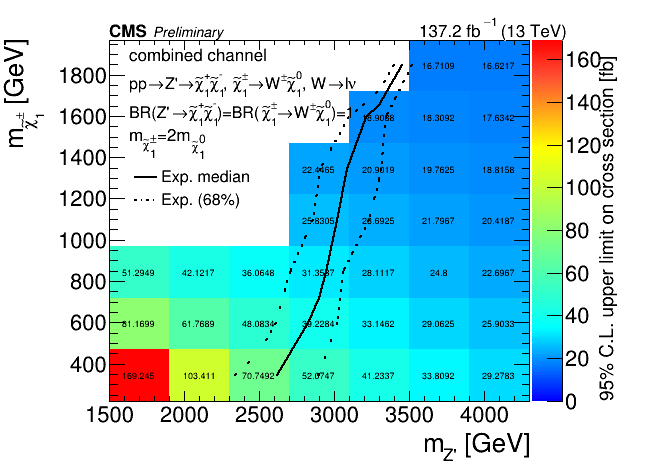

In [8]:
os.system("mkdir -p Combine/Plots")

c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetRightMargin(0.18)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)

for key in dic_limits:
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, float(dic_limits[key][2])*dic_xsec[key]*20*1000) # limit on production cross section
#     h2d1.SetBinContent(binx, biny, float(dic_limits[key][2])) # limit on signal strenth

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
# h2d1.GetZaxis().SetRangeUser(0,630)
# contours = array('d',[1])
h2d1.DrawCopy("colz text");
# h2d1.SetContour(1,contours);
# # h2d1.Draw("cont3 same");
# h2d1.Draw("colz same");
# h2d1.SetLineColor(rt.kBlack);
# h2d1.SetLineWidth(2);

# h2d.GetYaxis().SetTitleOffset(1.25)
list_graph[0].Draw("same")
list_graph[0].SetLineStyle(4)
list_graph[0].SetLineWidth(2)
list_graph[0].SetLineColor(rt.kBlack)
list_graph[1].Draw("same")
list_graph[1].SetLineStyle(1)
list_graph[1].SetLineWidth(2)
list_graph[2].Draw("same")
list_graph[2].SetLineStyle(4)
list_graph[2].SetLineWidth(2)
list_graph[2].GetYaxis().SetTitle("erer")

l = rt.TLegend(0.2,0.55,0.4,0.65)
l.SetBorderSize(0);
l.AddEntry(list_graph[1], "Exp. median", "l")
l.AddEntry(list_graph[2], "Exp. (68%)", "l")
l.Draw()
latex_1_=rt.TLatex()
latex_1_.SetTextAlign(11)
latex_1_.SetTextSize(0.04)
latex_1_.DrawLatexNDC(0.17,0.92,"#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}")
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.87, "#scale[0.5]{#font[42]{"+str_channel+" channel}}")
latex1=rt.TLatex()
latex1.DrawLatexNDC( 0.2,0.81, "#scale[0.47]{#font[40]{pp#rightarrowZ'#rightarrow#tilde#chi_{1}^{+}#tilde#chi_{1}^{-}, #tilde#chi_{1}^{#pm}#rightarrowW^{#pm}#tilde#chi_{1}^{0}, W#rightarrowl#nu}}")
latex2=rt.TLatex()
latex2.DrawLatexNDC( 0.2,0.75, "#scale[0.47]{#font[40]{BR(Z'#rightarrow#tilde#chi_{1}^{+}#tilde#chi_{1}^{-})=BR(#tilde#chi_{1}^{#pm}#rightarrowW^{#pm}#tilde#chi_{1}^{0}})=1}")
latex4=rt.TLatex()
latex4.DrawLatexNDC( 0.2,0.70, "#scale[0.5]{#font[40]{m_{#tilde#chi_{1}^{#pm}}=2m_{#tilde#chi_{1}^{0}}}}")
# latex3=rt.TLatex()
# latex3.DrawLatexNDC( 0.2,0.73, "#scale[0.5]{#font[42]{m_{#tilde#chi_{1}^{#pm}}=2m_{#tilde#chi_{1}^{0}}}}")
latex_2=rt.TLatex()
latex_2.SetTextAlign(11)
latex_2.SetTextSize(0.04)
latex_2.DrawLatexNDC(0.65,0.92,"#bf{#bf{"+str_lumi+" fb^{#font[122]{\55}1} (13 TeV)}}")
latex_3=rt.TLatex()
latex_3.SetTextAngle(90)
latex_3.SetTextSize(0.043)
latex_3.DrawLatexNDC(0.95,0.15,"95% C.L. upper limit on cross section [fb]")
# box=rt.TBox(0.7, 0.72, 0.73, 0.9)
# box.SetFillColor(rt.kRed)
# box.SetFillStyle(0)
# box.Draw("same")
# latex5=rt.TLatex()
# latex5.DrawLatexNDC( 0.7,0.70, "#scale[0.5]{#font[40]{test}}")
p2=rt.TPad("pad","",0.65,0.82,0.739,0.89)
# p2.Draw()
c1.Draw()
c1.SaveAs("Combine/Plots/limit_"+ERA+".pdf")